# PyTorch Audio vs Our Model

### Summary

Throughout this project, we have consistently used two different models for audio separation: our model (KaraokeExpert U-Net) and PyTorch Audio (HDemucs). In this notebook, we compare how the two models score in Signal-to-Distortion Ratio (SDR) on the same test set.

#### SDR

SDR measures the ratio of target energy to all error energy combined. This is the usual metric that is used for models like these.

In [1]:
import argparse
import csv
from pathlib import Path
from typing import Callable, Dict, List, Optional, Tuple
 
import numpy as np
import torch
import torchaudio
 
DEFAULT_TEST_ROOT = (
    r"C:\Users\chris\OneDrive\Desktop\senior-project\KaraokeExpert"
    r"\model\data\processed_data\pytorch_test"
)
EPS = 1e-8
 
Separator = Callable[[torch.Tensor], Tuple[torch.Tensor, torch.Tensor]]

In [2]:
def sdr(reference: torch.Tensor, estimate: torch.Tensor) -> float:
    num = torch.sum(reference**2) + EPS
    den = torch.sum((reference - estimate) ** 2) + EPS
    return (10 * torch.log10(num / den)).item()

def si_sdr(reference: torch.Tensor, estimate: torch.Tensor) -> float:
    ref = reference - reference.mean(dim=-1, keepdim=True)
    est = estimate - estimate.mean(dim=-1, keepdim=True)
    alpha = torch.sum(est * ref) / (torch.sum(ref**2) + EPS)
    target = alpha * ref
    noise = est - target
    return (10 * torch.log10((torch.sum(target**2) + EPS) / (torch.sum(noise**2) + EPS))).item()

In [3]:
def to_channels_first(arr: np.ndarray) -> torch.Tensor:
    x = torch.from_numpy(np.asarray(arr, dtype=np.float32))
    if x.ndim == 1:
        x = x.unsqueeze(0)
    elif x.ndim == 2 and x.shape[0] > x.shape[1]:
        x = x.T
    elif x.ndim != 2:
        raise ValueError(f"Unexpected waveform shape {tuple(arr.shape)}")
    return x.contiguous()

In [4]:
def load_sample(sample_dir: Path) -> Dict[str, torch.Tensor]:
    return {
        name: to_channels_first(np.load(sample_dir / f"{name}.npy"))
        for name in ("mixture", "vocals", "instrumental")
    }

In [5]:
def evaluate(
    separator: Separator,
    test_root: str = DEFAULT_TEST_ROOT,
    csv_path: Optional[str] = None,
) -> Dict[str, object]:
    sample_dirs = sorted(d for d in Path(test_root).iterdir() if d.is_dir())
    if not sample_dirs:
        raise FileNotFoundError(f"No sample folders found in {test_root}")

    rows: List[Dict[str, object]] = []
    for d in sample_dirs:
        data = load_sample(d)
        mix, voc_ref, ins_ref = data["mixture"], data["vocals"], data["instrumental"]

        voc_est, ins_est = separator(mix)
        voc_est, ins_est = voc_est.detach().cpu().float(), ins_est.detach().cpu().float()

        n = min(voc_ref.shape[-1], voc_est.shape[-1])
        ch = min(voc_ref.shape[0], voc_est.shape[0])
        voc_ref, ins_ref, mix_a = voc_ref[:ch, :n], ins_ref[:ch, :n], mix[:ch, :n]
        voc_est, ins_est = voc_est[:ch, :n], ins_est[:ch, :n]

        row = {
            "sample": d.name,
            "vocals_SDR": sdr(voc_ref, voc_est),
            "instrumental_SDR": sdr(ins_ref, ins_est),
            "vocals_SI_SDR": si_sdr(voc_ref, voc_est),
            "instrumental_SI_SDR": si_sdr(ins_ref, ins_est),
            "vocals_SDR_mixture_baseline": sdr(voc_ref, mix_a),
            "instrumental_SDR_mixture_baseline": sdr(ins_ref, mix_a),
        }
        rows.append(row)

    keys = [k for k in rows[0] if k != "sample"]
    mean_row = {"sample": "MEAN", **{k: float(np.mean([r[k] for r in rows])) for k in keys}}

    overall = (mean_row["vocals_SDR"] + mean_row["instrumental_SDR"]) / 2
    print(
        f"\nSDR score over {len(rows)} sample(s): "
        f"vocals {mean_row['vocals_SDR']:.2f} dB | "
        f"instrumental {mean_row['instrumental_SDR']:.2f} dB | "
        f"overall {overall:.2f} dB"
    )

    if csv_path:
        with open(csv_path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=["sample"] + keys)
            writer.writeheader()
            writer.writerows(rows + [mean_row])
    overall = (mean_row["vocals_SDR"] + mean_row["instrumental_SDR"]) / 2
    print(
        f"\nSDR score over {len(rows)} sample(s): "
        f"vocals {mean_row['vocals_SDR']:.2f} dB | "
        f"instrumental {mean_row['instrumental_SDR']:.2f} dB | "
        f"overall {overall:.2f} dB"
    )
    return {"per_sample": rows, "mean": mean_row}

In [6]:
@torch.no_grad()
def _hdemucs_chunked(model, mix, sample_rate, device, segment=10.0, overlap=0.1):
    """mix: (batch, channels, samples) -> (batch, n_sources, channels, samples)."""
    batch, channels, length = mix.shape
    chunk_len = int(sample_rate * segment * (1 + overlap))
    overlap_frames = int(overlap * sample_rate)
    fade = torchaudio.transforms.Fade(
        fade_in_len=0, fade_out_len=overlap_frames, fade_shape="linear"
    )
 
    final = torch.zeros(batch, len(model.sources), channels, length, device=device)
    start, end = 0, chunk_len
    while start < length - overlap_frames:
        out = fade(model(mix[:, :, start:end]))
        final[:, :, :, start : start + out.shape[-1]] += out
        if start == 0:
            fade.fade_in_len = overlap_frames
            start += chunk_len - overlap_frames
        else:
            start += chunk_len
        end += chunk_len
        if end >= length:
            fade.fade_out_len = 0
    return final

In [7]:
def make_hdemucs_separator(
    data_sample_rate: int = 44100, device: Optional[str] = None
) -> Separator:
    """Build a separator around HDEMUCS_HIGH_MUSDB_PLUS."""
    from torchaudio.pipelines import HDEMUCS_HIGH_MUSDB_PLUS
 
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    bundle = HDEMUCS_HIGH_MUSDB_PLUS
    model = bundle.get_model().to(device).eval()
    sources = list(model.sources)
    model_sr = bundle.sample_rate
    vocals_idx = sources.index("vocals")
    print(f"HDemucs sources: {sources} | model sample rate: {model_sr} | device: {device}")
 
    def separator(mix: torch.Tensor):
        in_channels = mix.shape[0]
        x = mix
        if data_sample_rate != model_sr:
            x = torchaudio.functional.resample(x, data_sample_rate, model_sr)
        if x.shape[0] == 1:
            x = x.repeat(2, 1)
 
        ref = x.mean(0)
        mean, std = ref.mean(), ref.std() + EPS
        x = ((x - mean) / std).unsqueeze(0).to(device)
 
        est = _hdemucs_chunked(model, x, model_sr, device)[0]  # (sources, 2, T)
        est = (est * std.to(device) + mean.to(device)).cpu()
 
        vocals = est[vocals_idx]
        instrumental = sum(est[i] for i in range(len(sources)) if i != vocals_idx)
 
        if data_sample_rate != model_sr:
            vocals = torchaudio.functional.resample(vocals, model_sr, data_sample_rate)
            instrumental = torchaudio.functional.resample(instrumental, model_sr, data_sample_rate)
        if in_channels == 1:
            vocals = vocals.mean(0, keepdim=True)
            instrumental = instrumental.mean(0, keepdim=True)
        return vocals, instrumental
 
    return separator

In [8]:
DEFAULT_CHECKPOINT = "resulting_model/unet_final.pth"


def karaoke_expert_separator(
    checkpoint: str = DEFAULT_CHECKPOINT, device: Optional[str] = None
) -> Separator:
    """Build a separator around our U-Net, using the same pipeline as convert.py."""
    from convert import Config, separate_channel
    from unet import UNetModel

    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    cfg = Config(model_path=checkpoint, device=device)
    model = UNetModel(in_channels=1, out_channels=2).to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    model.eval()
    print(f"KaraokeExpert U-Net: {checkpoint} | sample rate: {cfg.sr} | device: {device}")

    def separator(mix: torch.Tensor):
        # The U-Net works on mono spectrograms, so separate each channel independently
        vocals, instrumental = [], []
        for channel in mix.numpy():
            wav_v, wav_i = separate_channel(channel, model, cfg)
            vocals.append(torch.from_numpy(wav_v))
            instrumental.append(torch.from_numpy(wav_i))
        n = min(w.shape[-1] for w in vocals + instrumental)
        return (torch.stack([w[:n] for w in vocals]),
                torch.stack([w[:n] for w in instrumental]))

    return separator

In [9]:
SEPARATORS: Dict[str, Callable[..., Separator]] = {
    "hdemucs": make_hdemucs_separator,
    "karaoke_expert": karaoke_expert_separator,
}

In [10]:
separator = make_hdemucs_separator(data_sample_rate=44100)
results = evaluate(separator, csv_path="sdr_results.csv")

HDemucs sources: ['drums', 'bass', 'other', 'vocals'] | model sample rate: 44100 | device: cpu

SDR score over 50 sample(s): vocals 8.02 dB | instrumental 15.66 dB | overall 11.84 dB

SDR score over 50 sample(s): vocals 8.02 dB | instrumental 15.66 dB | overall 11.84 dB


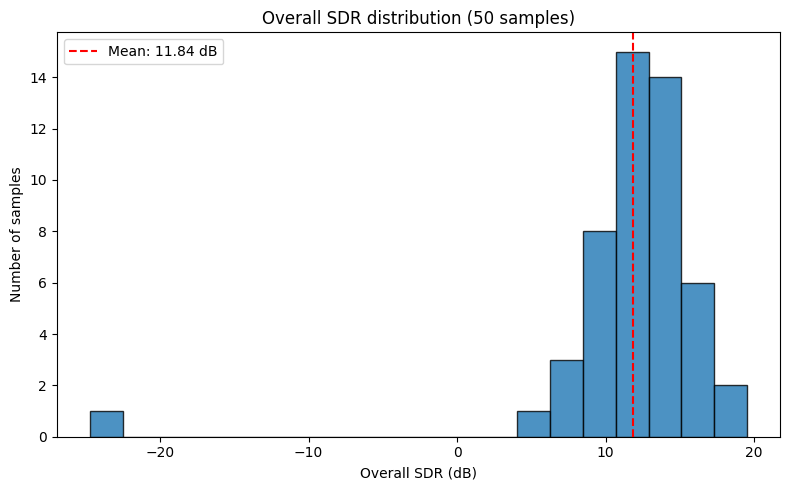

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sdr_results.csv")
df = df[df["sample"] != "MEAN"].copy()

df["overall_SDR"] = (df["vocals_SDR"] + df["instrumental_SDR"]) / 2
mean_score = df["overall_SDR"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["overall_SDR"], bins=20, edgecolor="black", alpha=0.8)
ax.axvline(mean_score, color="red", linestyle="--", label=f"Mean: {mean_score:.2f} dB")
ax.set_xlabel("Overall SDR (dB)")
ax.set_ylabel("Number of samples")
ax.set_title(f"Overall SDR distribution ({len(df)} samples)")
ax.legend()
plt.tight_layout()
plt.show()

### Our Model

Run the KaraokeExpert U-Net over the same test set (`DEFAULT_TEST_ROOT`).

In [ ]:
separator = karaoke_expert_separator()
results_ke = evaluate(separator, test_root=DEFAULT_TEST_ROOT, csv_path="sdr_results_karaoke_expert.csv")

In [ ]:
models = {"HDemucs": "sdr_results.csv", "KaraokeExpert": "sdr_results_karaoke_expert.csv"}

frames = {}
for name, path in models.items():
    m = pd.read_csv(path)
    m = m[m["sample"] != "MEAN"].copy()
    m["overall_SDR"] = (m["vocals_SDR"] + m["instrumental_SDR"]) / 2
    frames[name] = m

summary = pd.DataFrame({
    name: m[["vocals_SDR", "instrumental_SDR", "overall_SDR"]].mean()
    for name, m in frames.items()
})
print(summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["vocals_SDR", "instrumental_SDR", "overall_SDR"]):
    for name, m in frames.items():
        ax.hist(m[col], bins=20, alpha=0.6, edgecolor="black",
                label=f"{name} (mean {m[col].mean():.2f} dB)")
    ax.set_xlabel(f"{col.replace('_', ' ')} (dB)")
    ax.set_ylabel("Number of samples")
    ax.legend()
fig.suptitle("SDR: HDemucs vs KaraokeExpert")
plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path
import numpy as np
import torch

d = sorted(p for p in Path(DEFAULT_TEST_ROOT).iterdir() if p.is_dir())[0]
data = load_sample(d)
mix, voc, ins = data["mixture"], data["vocals"], data["instrumental"]

print("shapes:", mix.shape, voc.shape, ins.shape)
print("peak abs:", mix.abs().max().item(), voc.abs().max().item(), ins.abs().max().item())
print("mixture ≈ vocals + instrumental?  SDR of (v+i) vs mix:",
      round(sdr(mix, voc + ins), 2), "dB (should be very high, 30+)")

# Baselines on this sample
print("vocals baseline (mix as estimate):", round(sdr(voc, mix), 2), "dB")
print("instrumental baseline (mix as estimate):", round(sdr(ins, mix), 2), "dB")

# Model output on this sample
separator = make_hdemucs_separator(data_sample_rate=44100)
v_est, i_est = separator(mix)
n = min(voc.shape[-1], v_est.shape[-1]); ch = min(voc.shape[0], v_est.shape[0])
print("est shapes:", v_est.shape, i_est.shape)
print("vocals SDR:", round(sdr(voc[:ch, :n], v_est[:ch, :n]), 2))
print("instrumental SDR:", round(sdr(ins[:ch, :n], i_est[:ch, :n]), 2))

shapes: torch.Size([2, 1323000]) torch.Size([2, 1323000]) torch.Size([2, 1323000])
peak abs: 0.7100535035133362 0.5152646899223328 0.6260534524917603
mixture ≈ vocals + instrumental?  SDR of (v+i) vs mix: 26.64 dB (should be very high, 30+)
vocals baseline (mix as estimate): -2.75 dB
instrumental baseline (mix as estimate): 2.75 dB
HDemucs sources: ['drums', 'bass', 'other', 'vocals'] | model sample rate: 44100 | device: cpu
est shapes: torch.Size([2, 1323000]) torch.Size([2, 1323000])
vocals SDR: 9.28
instrumental SDR: 11.87
